Question: Does the first visit behaviour predict who comes back and who purchase within 7 days after their first visit without buys

- Data: 152860 new users arrived Nov 1st to Dec 24th.
    - Data for January is on hold for testing.
- Cohort, outcomes, inputs, rule and models are defined in `src/ga4case/model.py`

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import shap
import itertools
from sklearn.metrics import roc_auc_score

from ga4case.path import FIGURES
from ga4case.model import (
    OUTCOMES,
    load_first_visits,
    generate_input,
    rule_flag,
    logistic_model,
    xgboost_model,
    top_scored,
    flag_result,
)


In [2]:
# Load data: new users in Nov 1st to Dec 24th who did not buy in the first visit
target_table = load_first_visits("2020-11-01", "2020-12-25")
target_table.shape

(152860, 10)

In [3]:
# Training and validation sets: this split is based on arrival date not random
train = (target_table["first_visit_start"] < pd.Timestamp("2020-12-11")).to_numpy()
valid = ~train

target_table["part"] = np.where(
    train, "train: Nov 1 to Dec 10", "validation: Dec 11 to Dec 24"
)
target_table.groupby("part").agg(
    users=("came_back", "size"),
    came_back=("came_back", "sum"),
    pct_came_back=("came_back", lambda s: round(100 * s.mean(), 1)),
    purchase_later=("purchase_later", "sum"),
    pct_purchase_later=("purchase_later", lambda s: round(100 * s.mean(), 2)),
)

,users,came_back,pct_came_back,purchase_later,pct_purchase_later
part,,,,,
train: Nov 1 to Dec 10,108211,12143,11.2,631,0.58
validation: Dec 11 to Dec 24,44649,3673,8.2,247,0.55


In [4]:
# Inputs and simple rule: inputs are extraced from the first visit, rule is the baseline (flag a visitor who viewed a product or began checkout)
X = generate_input(target_table)
rule = rule_flag(target_table)
X.head(2)

,log_distinct_pages,log_active_seconds,viewed_product,searched,began_checkout,saw_error_page,landing:Home,landing:Google Online Store,landing:Apparel,landing:YouTube,landing:Google Dino Game Tee
0,0.693147,2.790244,0,0,0,0,1,0,0,0,0
1,0.693147,1.047319,0,0,0,0,1,0,0,0,0


In [5]:
def fit_and_score(model, outcome):
    model.fit(X[train], target_table.loc[train, outcome])
    return model.predict_proba(X[valid])[:, 1]

In [6]:
models, scores = {}, {}
for outcome in OUTCOMES:
    for name, model in [
        ("logistic regression", logistic_model()),
        ("xgboost", xgboost_model()),
    ]:
        scores[(name, outcome)] = fit_and_score(model, outcome)
        models[(name, outcome)] = model

In [7]:
probs = pd.DataFrame(
    {f"{name} | {outcome}": s for (name, outcome), s in scores.items()}
)
probs.head()

,logistic regression | came_back,xgboost | came_back,logistic regression | purchase_later,xgboost | purchase_later
0,0.107552,0.082896,0.002425,0.000865
1,0.052184,0.049726,0.000229,0.000344
2,0.134819,0.210741,0.005356,0.013795
3,0.089795,0.069569,0.001075,0.000850
4,0.200966,0.252997,0.012361,0.021847


In [8]:
n_rule = int(rule[valid].sum())

In [9]:
rows = []
for outcome in OUTCOMES:
    y = target_table.loc[valid, outcome].to_numpy()
    rows.append(
        {
            "outcome": outcome,
            "approach": "rule",
            "auc": roc_auc_score(y, rule[valid]),
            **flag_result(y, rule[valid]),
        }
    )
    for name in ["logistic regression", "xgboost"]:
        score = scores[(name, outcome)]
        rows.append(
            {
                "outcome": outcome,
                "approach": name,
                "auc": roc_auc_score(y, score),
                **flag_result(y, top_scored(score, n_rule)),
            }
        )

comparison = pd.DataFrame(rows).round(2)
comparison

,outcome,approach,auc,pct_average,pct_flagged,pct_outcome_among_flagged,times_average,cases_caught,pct_of_cases_caught
0,came_back,rule,0.59,8.23,18.0,15.98,1.94,1285,34.99
1,came_back,logistic regression,0.71,8.23,18.0,18.95,2.30,1523,41.46
2,came_back,xgboost,0.74,8.23,18.0,19.87,2.41,1597,43.48
3,purchase_later,rule,0.77,0.55,18.0,2.18,3.94,175,70.85
4,purchase_later,logistic regression,0.89,0.55,18.0,2.51,4.54,202,81.78
5,purchase_later,xgboost,0.91,0.55,18.0,2.54,4.59,204,82.59


In [10]:
# Check whether XGBoost changes with random seed or the model settings
rows = []
for seed in range(5):
    row = {"seed": seed}
    for outcome in OUTCOMES:
        y = target_table.loc[valid, outcome].to_numpy()
        score = fit_and_score(xgboost_model(seed=seed), outcome)
        row[f"cases_caught_{outcome}"] = flag_result(y, top_scored(score, n_rule))[
            "cases_caught"
        ]
    rows.append(row)

pd.DataFrame(rows).set_index("seed")

,cases_caught_came_back,cases_caught_purchase_later
seed,,
0,1597,204
1,1582,202
2,1551,205
3,1588,204
4,1563,204


In [11]:
# Check whether train with a small grid on the training dataset will affect on validation AUC
rows = []
for C in [0.001, 0.01, 0.1, 1.0, 10.0]:
    row = {"model": "logistic regression", "settings": f"C={C}"}
    for outcome in OUTCOMES:
        score = fit_and_score(logistic_model(C=C), outcome)
        row[f"auc_{outcome}"] = roc_auc_score(target_table.loc[valid, outcome], score)
    rows.append(row)

for max_depth, n_estimators, learning_rate in itertools.product(
    [2, 3, 5], [100, 300, 600], [0.03, 0.1]
):
    row = {
        "model": "xgboost",
        "settings": f"depth={max_depth}, trees={n_estimators}, rate={learning_rate}",
    }
    for outcome in OUTCOMES:
        score = fit_and_score(
            xgboost_model(max_depth, n_estimators, learning_rate), outcome
        )
        row[f"auc_{outcome}"] = roc_auc_score(target_table.loc[valid, outcome], score)
    rows.append(row)

tuning = pd.DataFrame(rows).round(3)
tuning.groupby("model")[["auc_came_back", "auc_purchase_later"]].agg(["min", "max"])


auc_came_back        auc_purchase_later       
                              min    max                min    max
model                                                             
logistic regression         0.710  0.712              0.890  0.895
xgboost                     0.732  0.743              0.887  0.910

In [12]:
# Coefficients on standardised inputs
pd.DataFrame(
    {
        outcome: models[("logistic regression", outcome)][-1].coef_[0]
        for outcome in OUTCOMES
    },
    index=X.columns,
).round(2)

,came_back,purchase_later
log_distinct_pages,0.31,0.11
log_active_seconds,0.09,1.16
viewed_product,0.10,0.38
searched,-0.08,-0.23
began_checkout,-0.25,-0.06
saw_error_page,0.04,-0.32
landing:Home,0.09,0.30
landing:Google Online Store,0.05,-0.00
landing:Apparel,-0.12,0.01
landing:YouTube,-0.22,-0.52


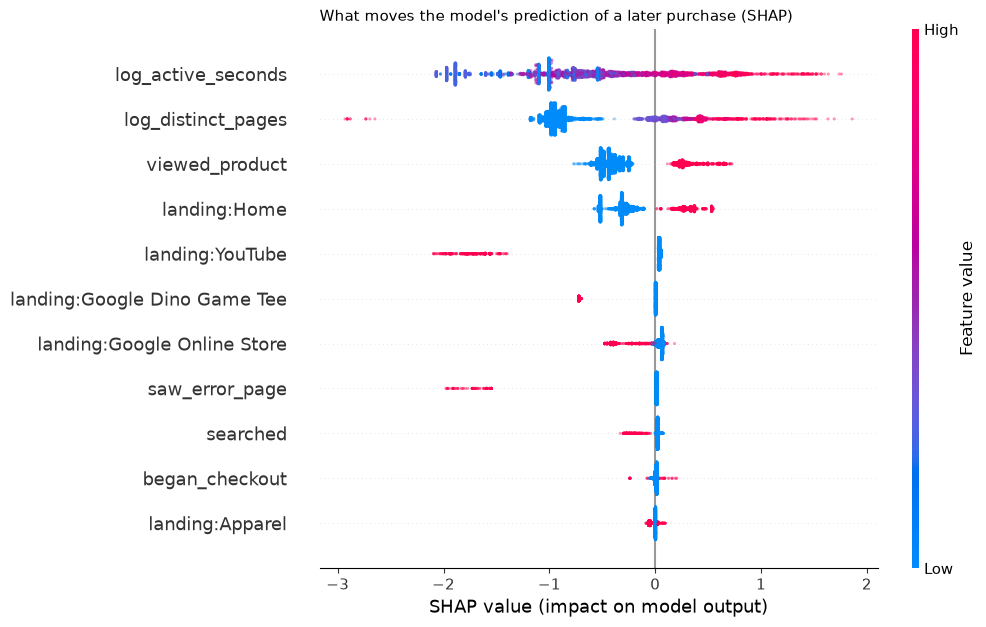

In [13]:
# SHAP on explain XGboost
explainer = shap.TreeExplainer(models[("xgboost", "purchase_later")])
sample = X[valid].sample(5000, random_state=0)
shap_values = explainer(sample)


shap.plots.beeswarm(
    shap_values, max_display=11, show=False, s=5, alpha=0.4, plot_size=(9, 7)
)
plt.title(
    "What moves the model's prediction of a later purchase (SHAP)",
    loc="left",
    fontsize=11,
)
plt.savefig(FIGURES / "shap_purchase_later.png", dpi=500, bbox_inches="tight")
plt.show()

In [14]:
shap_table = pd.DataFrame(
    shap_values.values, columns=sample.columns, index=sample.index
)

binary = [c for c in sample.columns if not c.startswith("log_")]
pd.DataFrame(
    {
        "users_yes": [int((sample[c] == 1).sum()) for c in binary],
        "push_when_yes": [shap_table.loc[sample[c] == 1, c].mean() for c in binary],
        "push_when_no": [shap_table.loc[sample[c] == 0, c].mean() for c in binary],
    },
    index=binary,
).round(2)


,users_yes,push_when_yes,push_when_no
viewed_product,906,0.32,-0.42
searched,245,-0.21,0.02
began_checkout,60,-0.02,0.01
saw_error_page,88,-1.70,0.01
landing:Home,1135,0.32,-0.33
landing:Google Online Store,845,-0.27,0.05
landing:Apparel,883,-0.03,0.00
landing:YouTube,466,-1.71,0.04
landing:Google Dino Game Tee,672,-0.72,0.00


In [15]:
raw = target_table.loc[sample.index]

bands = pd.cut(
    raw["active_seconds"],
    [-0.1, 0, 10, 60, 300, np.inf],
    labels=["0 s", "up to 10 s", "10-60 s", "1-5 min", "over 5 min"],
)
shap_table["log_active_seconds"].groupby(bands).agg(
    users="size", mean_push="mean"
).round(2)

,users,mean_push
active_seconds,,
0 s,907,-0.94
up to 10 s,1853,-1.24
10-60 s,1370,-0.49
1-5 min,674,0.43
over 5 min,196,1.03


In [16]:
bands = pd.cut(
    raw["distinct_pages"],
    [-0.1, 0, 1, 2, 5, 10, 30, np.inf],
    labels=["0", "1", "2", "3-5", "6-10", "11-30", "over 30"],
)
shap_table["log_distinct_pages"].groupby(bands).agg(
    users="size", mean_push="mean"
).round(2)


,users,mean_push
distinct_pages,,
0,4,-0.95
1,3553,-0.94
2,595,0.03
3-5,543,0.33
6-10,210,0.62
11-30,80,1.17
over 30,15,-2.30


In [17]:
base = float(np.ravel(shap_values.base_values)[0])
base, 1 / (1 + np.exp(-base))

(-5.18305778503418, np.float64(0.0055795177756309405))

Findings:
- It is easier to predict the purchase later than come_back according the AUC:
    - 0.89 vs 0.71 in Logistic regression.
    - 0.91 VS 0.74 in XGBoost.
- The baseline from rule caught 70.85% (175 of 247 later purchasers) later buyers and 34.99% come_back (1285 of 3673 come_back) from validation dataset.
    - Rule flagged 18% of visitors
- Both logistic regression and XGBoost add a moderate gain compared with the baseline:
    - Logistic regression caught 1523 (41.46%) come_back and 202 later buyers (81.78%), 
    - XGBoost caught 1597 come_back and 204 later buyers.
    - Compared with Logistic regression, the performance of XGBoost only account for around one to two percentage points higher.
- Both Logistic Regression and XGBoost could be used for the testing, but Logistic regression is simple when comes to explaination. Therefore, Logistic regression would be used for testing. 
- From XGBoost: active time, distinct pages, viewed product and landing home page move the prediction of the model:
    - over 1 min favors the prediction.
    - Landing on YouTube lowers or saw error page lowers the prediction.
- This model tells who might buy but not the reason to buy: predictive not causal.
- Whether error page affected sales needs further tests.
- Limitations: validation dataset showed a gap on return rate when compared with training dataset: 8.2% vs 11.2%.
